# Manual Logistic Regression

## Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Importing dataset

In [ ]:
exam_df=pd.read_csv(r'../Projects_and_practice/Datasets/exam.csv')
exam_df.head()

,study_hours,pass_fail
0,0.50,0
1,0.75,0
2,1.00,0
3,1.25,0
4,1.50,0


## Shuffling data to have both classes for prediction

In [ ]:
np.random.seed(45)
indices=np.random.permutation(len(exam_df))
exam_df=exam_df.iloc[indices]
exam_df.to_csv('shuffled_exam.csv', index=False)

In [ ]:
exam_df=pd.read_csv('shuffled_exam.csv')
exam_df.head()

,study_hours,pass_fail
0,3.25,1
1,4.50,1
2,5.50,1
3,1.00,0
4,4.25,1


## Splitting Train and Test Data

In [ ]:
train_number=int(len(exam_df) * 0.8)-1 

In [ ]:
train_df=exam_df.iloc[:train_number,:]
test_df=exam_df.iloc[train_number:,:]
test_df.to_csv('exam(test dataset).csv', index=False)

## Splitting Feature and Label

In [ ]:
x_train=train_df.iloc[:,0]
y_train=train_df.iloc[:,1]

## Standardization

In [ ]:
x_mean=x_train.mean()
x_std=np.std(x_train)
x_scaled=(x_train-x_mean)/x_std

In [ ]:
ones_arr=np.ones(train_number)
x_train_matrix=np.stack((ones_arr,x_scaled), axis=1)

## Dataset visualization

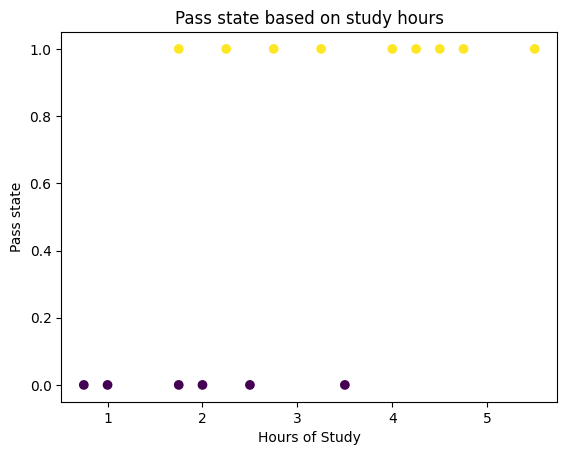

In [ ]:
plt.title('Pass state based on study hours')
plt.xlabel('Hours of Study')
plt.ylabel('Pass state')
plt.scatter(x_train, y_train, c=y_train)

## Function definitions

In [ ]:
def y_hat(x_,w_):
    m=x_ @ w_.T
    m=np.clip(m,-500, 500)
    sigmoid=1.0 /(1.0 + np.exp(-m))
    return sigmoid

In [ ]:
def Loss_func(y, y_):
    y_= np.clip(y_, 1e-15, 1-(1e-15))
    Loss= -(y.T @ np.log(y_) + (1-y).T @ np.log(1-y_)) / y.shape[0]
    return Loss

In [ ]:
def gradient_descent(x, y_,y):
    grad=(x.T @ (y_-y)) / y.shape[0]
    return grad

## Initializing

In [ ]:
np.random.seed(10)
w=np.array([np.random.randn(),np.random.randn()])
N_epochs=3000
etha=0.01

## For mini batch

In [ ]:
batch_num=4
batch_size=int(x_train_matrix.shape[0]/batch_num)

In [ ]:
epochs=5

## Optimization loop

In [ ]:
for epoch in range(N_epochs):
    batch_loss=[]
    np.random.seed(epoch)
    indices = np.random.permutation(x_train_matrix.shape[0])
    X_shuffled = x_train_matrix[indices]
    y_shuffled = y_train[indices]

    for start in range(0,x_train_matrix.shape[0], batch_size):
        
        end=start+batch_size
        x_batch=X_shuffled[start:end]
        y_batch=y_shuffled[start:end]

        y_pred=y_hat(x_batch, w)

        grad=gradient_descent(x_batch,y_pred, y_batch)
        w-=etha*grad
        
        loss=Loss_func(y_batch, y_pred)
        batch_loss.append(loss)

    batch_avg=np.mean(batch_loss)
    if (epoch)%100==0: print(f'epoch: {epoch}\tw0= {w[0]:.4f}\tw1= {w[1]:.4f}\tLoss= {batch_avg:.4f}')
print(f'epoch: {epoch+1}\tw0= {w[0]:.4f}\tw1= {w[1]:.4f}\tLoss= {batch_avg:.4f}')       

epoch: 0	w0= 1.3265	w1= 0.7210	Loss= 0.5900
epoch: 100	w0= 0.9709	w1= 1.1420	Loss= 0.4840
epoch: 200	w0= 0.8058	w1= 1.3768	Loss= 0.4555
epoch: 300	w0= 0.7307	w1= 1.5213	Loss= 0.4464
epoch: 400	w0= 0.6989	w1= 1.6176	Loss= 0.4429
epoch: 500	w0= 0.6884	w1= 1.6853	Loss= 0.4413
epoch: 600	w0= 0.6882	w1= 1.7351	Loss= 0.4404
epoch: 700	w0= 0.6929	w1= 1.7727	Loss= 0.4400
epoch: 800	w0= 0.6995	w1= 1.8018	Loss= 0.4397
epoch: 900	w0= 0.7066	w1= 1.8248	Loss= 0.4395
epoch: 1000	w0= 0.7134	w1= 1.8432	Loss= 0.4393
epoch: 1100	w0= 0.7196	w1= 1.8581	Loss= 0.4392
epoch: 1200	w0= 0.7250	w1= 1.8702	Loss= 0.4392
epoch: 1300	w0= 0.7298	w1= 1.8802	Loss= 0.4391
epoch: 1400	w0= 0.7339	w1= 1.8885	Loss= 0.4391
epoch: 1500	w0= 0.7374	w1= 1.8953	Loss= 0.4391
epoch: 1600	w0= 0.7403	w1= 1.9010	Loss= 0.4391
epoch: 1700	w0= 0.7428	w1= 1.9057	Loss= 0.4391
epoch: 1800	w0= 0.7449	w1= 1.9096	Loss= 0.4391
epoch: 1900	w0= 0.7467	w1= 1.9129	Loss= 0.4391
epoch: 2000	w0= 0.7482	w1= 1.9157	Loss= 0.4391
epoch: 2100	w0= 0.7494	w1

## Save model parameters

In [ ]:
np.savetxt('Weights for sigmoid variable',w)

## Loading test data

In [ ]:
df_test=pd.read_csv('exam(test dataset).csv', )
df_test.head()

,study_hours,pass_fail
0,1.50,0
1,5.00,1
2,0.50,0
3,1.25,0
4,3.00,0


## Spliting & Standardization & creating a x0 column

In [ ]:
x_test=df_test[['study_hours']]
y_test=df_test.iloc[:,-1]

x_test_scaled=(x_test-x_mean)/x_std
x_test_matrix=np.hstack((np.ones(5).reshape(5,1),x_test_scaled))

## Loading Model parameters

In [ ]:
w_model=np.loadtxt("Weights for sigmoid variable")

## Predicting test data by model

In [ ]:
y_pred=y_hat(x_test_matrix, w_model)
y_pred=(y_pred>=0.5).astype(int)
y_pred

array([0, 1, 0, 0, 1])

## Accuracy func

In [ ]:
def accuracy(yt,y_pre):
    acc=float(np.mean(y_pre==yt))
    return acc

## Evaluation

In [ ]:
print(f'Accuracy Score for this model is: {accuracy(y_test, y_pred)}')

Accuracy Score for this model is: 0.8
